# Assignment 5
Training Word2Vec, fastText, Doc2Vec models and applying K-Means clustering.

*Note: Run the cell below to install required packages if you are getting 'Import could not be resolved' errors.*

In [ ]:
!pip install gensim scikit-learn numpy pandas matplotlib

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from gensim.models import Word2Vec, FastText
from gensim.models.doc2vec import Doc2Vec, TaggedDocument
from sklearn.cluster import KMeans
from sklearn.metrics.pairwise import cosine_similarity
import codecs
from IPython.display import display

# Load the actual 1,000,000 sentences dataset
file_path = r"c:\Users\krish\Desktop\LLMS\LAB3(13-8-26)\gujarati_sentences.txt"
with codecs.open(file_path, "r", encoding="utf-8") as f:
    sentences = [line.strip().split() for line in f.readlines() if line.strip()]

# Split into train, validation, and test sets
training_data = sentences[:-2000]
validation_data = sentences[-2000:-1000]
test_data = sentences[-1000:]

print(f"Loaded {len(training_data)} training sentences, {len(validation_data)} validation sentences, {len(test_data)} test sentences.")

Loaded 1098000 training sentences, 1000 validation sentences, 1000 test sentences.


## Task 1: Train the Models
### 1a. Train Word2Vec

In [9]:
w2v_model = Word2Vec(sentences=training_data, vector_size=100, window=5, min_count=2, workers=4)

### 1b. Train fastText

In [10]:
ft_model = FastText(sentences=training_data, vector_size=100, window=5, min_count=2, workers=4)

### 1c. Train Doc2Vec

In [11]:
tagged_data = [TaggedDocument(words=_d, tags=[str(i)]) for i, _d in enumerate(training_data)]
d2v_model = Doc2Vec(vector_size=100, window=5, min_count=2, workers=4, epochs=10)
d2v_model.build_vocab(tagged_data)
d2v_model.train(tagged_data, total_examples=d2v_model.corpus_count, epochs=d2v_model.epochs)

## Task 2: Clustering and Similarity
### 2a. K-means clustering on words (with Visualization)

c:\Users\krish\AppData\Local\Programs\Python\Python313\Lib\site-packages\joblib\externals\loky\backend\context.py:131: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\krish\AppData\Local\Programs\Python\Python313\Lib\site-packages\joblib\externals\loky\backend\context.py", line 247, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_win32()
  File "c:\Users\krish\AppData\Local\Programs\Python\Python313\Lib\site-packages\joblib\externals\loky\backend\context.py", line 299, in _count_physical_cores_win32
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\krish\AppData\Local\Programs\Python\Pytho

Top 20 Words per Cluster:


,Cluster,Top 20 Words
0,0,"સમાનતા, ક્ષમતાઓ, ક્રિયાઓ, મૂલ્યો, ખ્યાલો, જીવન..."
1,1,"छे, #SwamiVivekanandaJayanti, वैराग, માણેજા,, ..."
2,2,"મેન્સ, રમાયેલ, ચેમ્પિયન્સ, સનરાઈઝર્સ, રમાયેલા,..."
3,3,"छे, આઈસીઆઈસીઆઇ, #SwamiVivekanandaJayanti, મેળવ..."
4,4,"45, ૪૫, ૧૫, ૨૫, 25, ૨૦, ૧૭, ૩૦, 16, ૧૮, 13, 17..."
5,5,"ટેક, સર્વિસીસ, સર્વિસ,, ફાઇનાન્સિયલ, સર્વિસિસ,..."
6,6,"એક્ટ્રેસ, કરિશ્મા, નેહા, કરણ, કરીના, એક્ટર, સો..."
7,7,"જગદીશ, જીતેન્દ્ર, પ્રવીણ, ચૌધરી,, જોશી,, રાજેન..."
8,8,"બાહ્ય, જટિલ, કાર્યાત્મક, અસામાન્ય, બહુવિધ, વ્ય..."
9,9,"નામદાર, જાહેરહિતની, વડી, સીબીઆઇ, રિટ, અરજદારે,..."


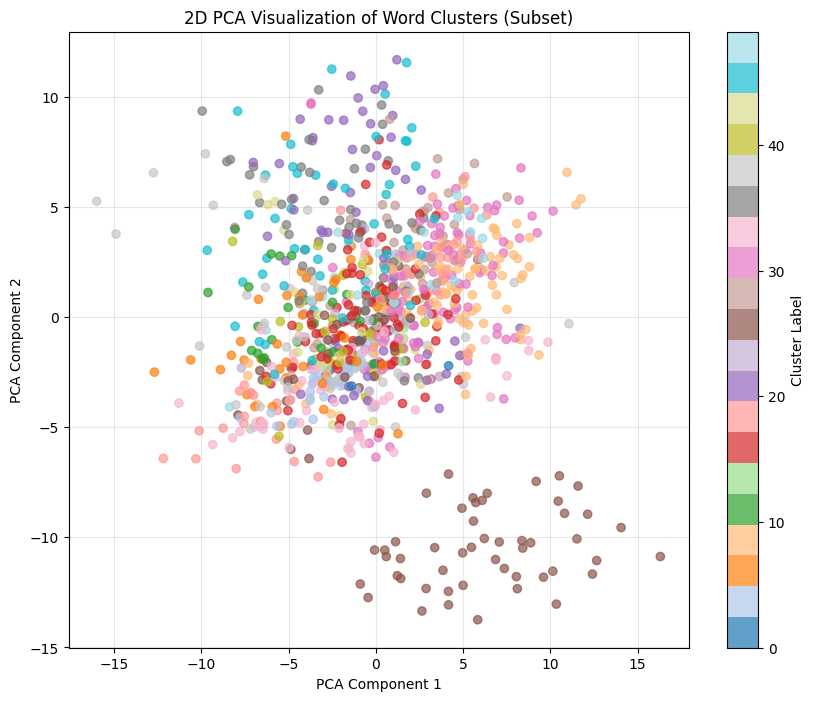

In [12]:
word_vectors = w2v_model.wv.vectors
vocab = w2v_model.wv.index_to_key

# Choose the number of clusters (K)
num_clusters = 50 
kmeans = KMeans(n_clusters=num_clusters, random_state=42)
kmeans.fit(word_vectors)

# 1. Represent each cluster with 20 closest words using a Pandas DataFrame for neat display
cluster_data = []
for i in range(num_clusters):
    centroid = kmeans.cluster_centers_[i]
    similar_words = w2v_model.wv.similar_by_vector(centroid, topn=20)
    words_only = [word for word, score in similar_words]
    cluster_data.append({"Cluster": i, "Top 20 Words": ", ".join(words_only)})

df_clusters = pd.DataFrame(cluster_data)
print("Top 20 Words per Cluster:")
display(df_clusters)

# 2. Visualize the clusters using PCA (plotting a subset of 1000 words for clarity)
subset_words = vocab[:1000]
subset_vectors = np.array([w2v_model.wv[w] for w in subset_words])
subset_labels = kmeans.predict(subset_vectors)

pca = PCA(n_components=2)
reduced_vectors = pca.fit_transform(subset_vectors)

plt.figure(figsize=(10, 8))
scatter = plt.scatter(reduced_vectors[:, 0], reduced_vectors[:, 1], c=subset_labels, cmap='tab20', alpha=0.7)
plt.title("2D PCA Visualization of Word Clusters (Subset)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.colorbar(scatter, label="Cluster Label")
plt.grid(True, alpha=0.3)
plt.show()

### 2b. Represent sentences as vectors and find closest sentences (Tabular Output)

In [13]:
def sentence_to_vector_w2v(sentence, model):
    vectors = [model.wv[word] for word in sentence if word in model.wv]
    if len(vectors) == 0:
        return np.zeros(model.vector_size)
    return np.mean(vectors, axis=0)

subset_size = 10000
train_subset = training_data[:subset_size]
train_vecs_w2v = np.array([sentence_to_vector_w2v(s, w2v_model) for s in train_subset])
train_vecs_d2v = np.array([d2v_model.dv[str(i)] for i in range(subset_size)])

def get_closest_sentences_df(query_sentences, model_type="w2v"):
    results = []
    for sentence in query_sentences:
        if model_type == "w2v":
            query_vec = sentence_to_vector_w2v(sentence, w2v_model)
            similarities = cosine_similarity([query_vec], train_vecs_w2v)
        else:
            query_vec = d2v_model.infer_vector(sentence)
            similarities = cosine_similarity([query_vec], train_vecs_d2v)
            
        closest_idx = np.argmax(similarities)
        results.append({
            "Query Sentence": " ".join(sentence),
            "Closest Matching Sentence": " ".join(train_subset[closest_idx]),
            "Similarity Score": float(similarities[0][closest_idx])
        })
    return pd.DataFrame(results)

print("========== Word Embeddings (Word2Vec) ==========")
print("\n--- Validation Set (Sample) ---")
display(get_closest_sentences_df(validation_data[:5], "w2v"))

print("\n--- Test Set (Sample) ---")
display(get_closest_sentences_df(test_data[:5], "w2v"))

print("\n========== Doc2Vec Embeddings ==========")
print("\n--- Validation Set (Sample) ---")
display(get_closest_sentences_df(validation_data[:5], "d2v"))

print("\n--- Test Set (Sample) ---")
display(get_closest_sentences_df(test_data[:5], "d2v"))

========== Word Embeddings (Word2Vec) ==========

--- Validation Set (Sample) ---


,Query Sentence,Closest Matching Sentence,Similarity Score
0,200 9 - 18 મે 2014) રહી.,હેમ પ્રોસ્ક્યુટ્ટો - 3 સ્લાઇસેસ;,0.781059
1,૨૪ : સુપ્રીમ કોર્ટમાં ચાલી રહેલા અયોધ્યા કેસ સ...,અપીલને ધ્યાને લીધા બાદ ગુજરાત હાઇકોર્ટના ચીફ જ...,0.789497
2,સુપ્રીમ કોર્ટે આ સંદર્ભમાં ચુકાદો આપવાની તૈયાર...,કોર્ટે મંગળવારે સુષ્મિતાને ચૂંટણી પંચના નિર્ણય...,0.811941
3,મસ્જિદમાં નમાઝ અદા કરવાની બાબત ઇસ્લામનો આંતરિક...,"મિલો પુરવઠાના ભરાવાના લીધે સંઘર્ષ કરી રહી છે, ...",0.850032
4,અયોધ્યામાં રામમંદિર-બાબરી મસ્જિદ વિવાદ સુપ્રીમ...,ટાઈટલ વિવાદ સાથે સંબંધીત મામલો સુપ્રીમ કોર્ટમા...,0.846922



--- Test Set (Sample) ---


,Query Sentence,Closest Matching Sentence,Similarity Score
0,આમાં મોટી સંખ્યામાં ઉગ્રવાદી માર્યા ગયા હતા.,નવરાત્રિમાં ખેલૈયાઓ મોટી સંખ્યામાં ઉમટી પડ્યા ...,0.841285
1,આ તમામ ઉગ્રવાદી ભારત દ્વારા બનાવવામાં આવી રહેલ...,મુંબઈ ઈન્ડીયન્સ દ્વારા 163 રનના રાખવામાં આવેલા...,0.771076
2,જામકંડોરણાઃ આખા સૌરાષ્ટ્ર પંથકમાં ભારે વરસાદના...,તળાજા પંથકમાં પણ વરસાદ પડતા વાતાવરણમાં ઠંડક પ્...,0.794478
3,રામપર ગામ પાસે ૨૯મીએ કાર તણાતા બે મહિલાના મૃત્...,પાવીજેતપુર તાલુકાના રાયપુર ગામના મિથુનભાઇ નાયક...,0.806177
4,એક મહિલા લાપતા થતાં તરવૈયા દ્વારા શોધખોળ ચાલુ છે.,શહેરના યાજ્ikિક રોડની એક વૈભવી હોટલમાં નગ્ન મહ...,0.765002



========== Doc2Vec Embeddings ==========

--- Validation Set (Sample) ---


,Query Sentence,Closest Matching Sentence,Similarity Score
0,200 9 - 18 મે 2014) રહી.,મૃતકોની સંખ્યા 6 છે.,0.563725
1,૨૪ : સુપ્રીમ કોર્ટમાં ચાલી રહેલા અયોધ્યા કેસ સ...,ઉલ્લેખનીય છે કે ગત બે મહિનામાં બાળકના અને માતા...,0.493851
2,સુપ્રીમ કોર્ટે આ સંદર્ભમાં ચુકાદો આપવાની તૈયાર...,તેવો પ્રશ્ન ચર્ચાઈ રહ્યો છે.,0.820308
3,મસ્જિદમાં નમાઝ અદા કરવાની બાબત ઇસ્લામનો આંતરિક...,"રાજભવનમાં રાજ્યપાલ,મુખ્યપ્રધાનના હસ્તે લોકાર્પણ",0.715226
4,અયોધ્યામાં રામમંદિર-બાબરી મસ્જિદ વિવાદ સુપ્રીમ...,ભારત અને ચીનની વચ્ચે તણાવની સ્થિતિ જોવા મળી રહ...,0.862948



--- Test Set (Sample) ---


,Query Sentence,Closest Matching Sentence,Similarity Score
0,આમાં મોટી સંખ્યામાં ઉગ્રવાદી માર્યા ગયા હતા.,ભારત અને ચીનની વચ્ચે તણાવની સ્થિતિ જોવા મળી રહ...,0.831019
1,આ તમામ ઉગ્રવાદી ભારત દ્વારા બનાવવામાં આવી રહેલ...,આ તમામ એથ્લેટ્સ પાસે કોઇ દેશ નહોતો અને તેમને સ...,0.473679
2,જામકંડોરણાઃ આખા સૌરાષ્ટ્ર પંથકમાં ભારે વરસાદના...,બસ ચાલક બસ મૂકીને નાસી ગયો હતો.,0.843521
3,રામપર ગામ પાસે ૨૯મીએ કાર તણાતા બે મહિલાના મૃત્...,ભારત અને ચીનની વચ્ચે તણાવની સ્થિતિ જોવા મળી રહ...,0.844609
4,એક મહિલા લાપતા થતાં તરવૈયા દ્વારા શોધખોળ ચાલુ છે.,આ મિસાઈલને ડિફેન્સ રિસર્ચ એન્ડ ડેવલપમેન્ટ ઓર્ગ...,0.820007
